### Import libraries:

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# BigQuery connection
from google.cloud import bigquery

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", None)

# Visualization settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


### Connect to BigQuery :

In [2]:
# Google Cloud Project
PROJECT_ID = "ecommerce-sales-nabin-2026"

# Initialize BigQuery client
client = bigquery.Client(project=PROJECT_ID)

# Verify connection
print("BigQuery connection successful.")
print("Project ID:", client.project)

BigQuery connection successful.
Project ID: ecommerce-sales-nabin-2026


### Define source tables :

In [3]:
TABLES = {
    "users": "devflow_raw.users",
    "organizations": "devflow_raw.organizations",
    "product_events": "devflow_raw.product_events",
    "feature_usage": "devflow_raw.feature_usage",
    "api_usage": "devflow_raw.api_usage",
    "subscriptions": "devflow_raw.subscriptions",
    "experiment_assignments": "devflow_raw.experiment_assignments"
}

print("Source tables configured:")
for name, table in TABLES.items():
    print(f"{name}: {table}")

Source tables configured:
users: devflow_raw.users
organizations: devflow_raw.organizations
product_events: devflow_raw.product_events
feature_usage: devflow_raw.feature_usage
api_usage: devflow_raw.api_usage
subscriptions: devflow_raw.subscriptions
experiment_assignments: devflow_raw.experiment_assignments


### Load the source tables :

In [4]:
PROJECT_ID = "ecommerce-sales-nabin-2026"

dataframes = {}

for name, table in TABLES.items():

    query = f"""
    SELECT *
    FROM `{PROJECT_ID}.{table}`
    """

    dataframes[name] = client.query(query).to_dataframe()

    print(
        f"{name}: "
        f"{dataframes[name].shape[0]:,} rows, "
        f"{dataframes[name].shape[1]} columns"
    )

users: 10,000 rows, 7 columns
organizations: 1,500 rows, 6 columns
product_events: 80,000 rows, 8 columns
feature_usage: 20,041 rows, 6 columns
api_usage: 50,000 rows, 8 columns
subscriptions: 1,500 rows, 7 columns
experiment_assignments: 6,000 rows, 5 columns


### Inspect the loaded data :

In [5]:
for name, df in dataframes.items():

    print("\n" + "=" * 60)
    print("TABLE:", name)
    print("=" * 60)

    display(df.head())


TABLE: users


,user_id,organization_id,signup_date,country,user_role,acquisition_channel,is_verified
0,1398,302,2024-01-10,Germany,Admin,Organic,1
1,9381,194,2024-01-18,Singapore,Admin,Paid Ads,1
2,2037,424,2024-01-23,Singapore,Admin,Social Media,0
3,9249,718,2024-01-25,Japan,Admin,Organic,0
4,1565,469,2024-02-02,Japan,Admin,Referral,1



TABLE: organizations


,organization_id,organization_name,industry,company_size,created_date,country
0,23,Organization_23,E-commerce,Medium,2025-07-11,Bangladesh
1,106,Organization_106,E-commerce,Small,2024-01-08,Bangladesh
2,126,Organization_126,E-commerce,Small,2024-06-27,Bangladesh
3,171,Organization_171,E-commerce,Enterprise,2024-12-06,Bangladesh
4,258,Organization_258,E-commerce,Small,2025-02-22,Bangladesh



TABLE: product_events


,event_id,user_id,event_name,event_timestamp,session_id,platform,device_type,event_properties
0,17609,7861,analytics_dashboard_viewed,2024-01-31,SESSION_17609,Web,Desktop,failure
1,49212,2507,analytics_dashboard_viewed,2024-02-20,SESSION_49212,Web,Desktop,feature_interaction
2,19018,8748,analytics_dashboard_viewed,2024-02-21,SESSION_19018,IDE,Desktop,success
3,22238,6657,analytics_dashboard_viewed,2024-02-25,SESSION_22238,Web,Desktop,integration_action
4,4883,1312,analytics_dashboard_viewed,2024-02-27,SESSION_4883,Web,Mobile,page_view


... (4 outputs left out)


TABLE: subscriptions


,subscription_id,organization_id,plan_type,subscription_status,monthly_price,start_date,end_date
0,1,1,Free,Active,0.0,2024-09-13,NaT
1,5,5,Free,Active,0.0,2025-03-06,NaT
2,6,6,Free,Active,0.0,2026-01-11,NaT
3,7,7,Free,Active,0.0,2024-11-12,NaT
4,14,14,Free,Active,0.0,2024-11-30,NaT



TABLE: experiment_assignments


,assignment_id,experiment_id,user_id,variant,assigned_at
0,5440,EXP_FEATURE_ONBOARDING_001,5058,Control,2024-03-31
1,2881,EXP_FEATURE_ONBOARDING_001,1202,Control,2024-04-13
2,4310,EXP_FEATURE_ONBOARDING_001,381,Control,2024-04-15
3,4492,EXP_FEATURE_ONBOARDING_001,3951,Control,2024-04-19
4,4986,EXP_FEATURE_ONBOARDING_001,5776,Control,2024-04-25


### Check missing values in every table:

In [6]:
# Missing Value Analysis

missing_value_results = []

for table_name, df in dataframes.items():

    for column in df.columns:

        missing_count = df[column].isnull().sum()

        missing_percentage = (
            missing_count / len(df) * 100
            if len(df) > 0 else 0
        )

        missing_value_results.append({
            "table_name": table_name,
            "column_name": column,
            "total_rows": len(df),
            "missing_values": missing_count,
            "missing_percentage": round(missing_percentage, 2)
        })

df_missing_values = pd.DataFrame(missing_value_results)

display(
    df_missing_values[
        df_missing_values["missing_values"] > 0
    ].sort_values(
        by="missing_percentage",
        ascending=False
    )
)

,table_name,column_name,total_rows,missing_values,missing_percentage
41,subscriptions,end_date,1500,1043,69.53


### Calculate missing-value summary by table :

In [7]:
# Missing Value Summary by Table

missing_summary = []

for table_name, df in dataframes.items():

    total_cells = df.size
    total_missing = df.isnull().sum().sum()

    missing_percentage = (
        total_missing / total_cells * 100
        if total_cells > 0 else 0
    )

    missing_summary.append({
        "table_name": table_name,
        "total_rows": len(df),
        "total_columns": len(df.columns),
        "total_missing_values": total_missing,
        "missing_percentage": round(missing_percentage, 2)
    })

df_missing_summary = pd.DataFrame(missing_summary)

display(df_missing_summary)

,table_name,total_rows,total_columns,total_missing_values,missing_percentage
0,users,10000,7,0,0.00
1,organizations,1500,6,0,0.00
2,product_events,80000,8,0,0.00
3,feature_usage,20041,6,0,0.00
4,api_usage,50000,8,0,0.00
5,subscriptions,1500,7,1043,9.93
6,experiment_assignments,6000,5,0,0.00


### Visualize missing values :

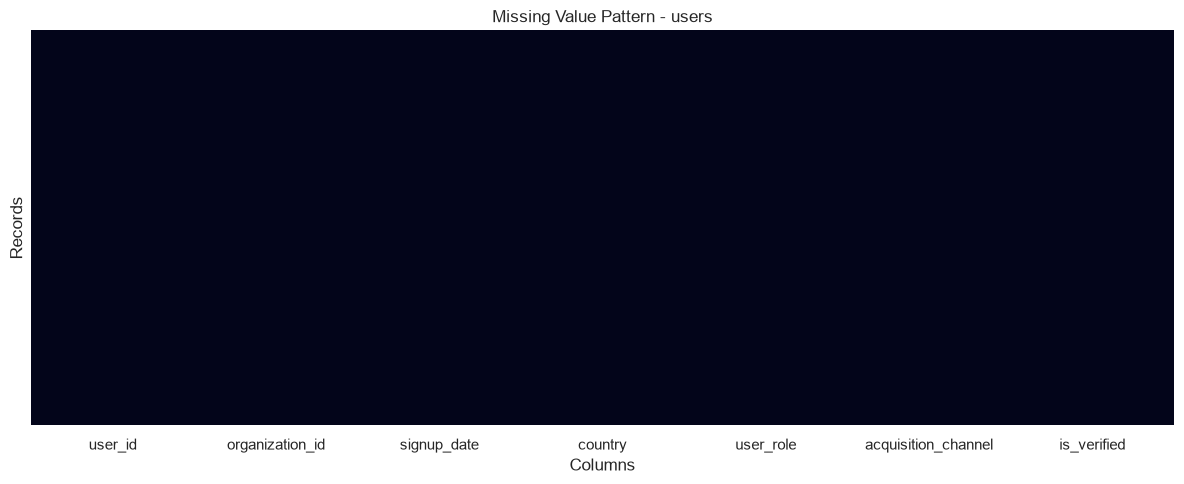

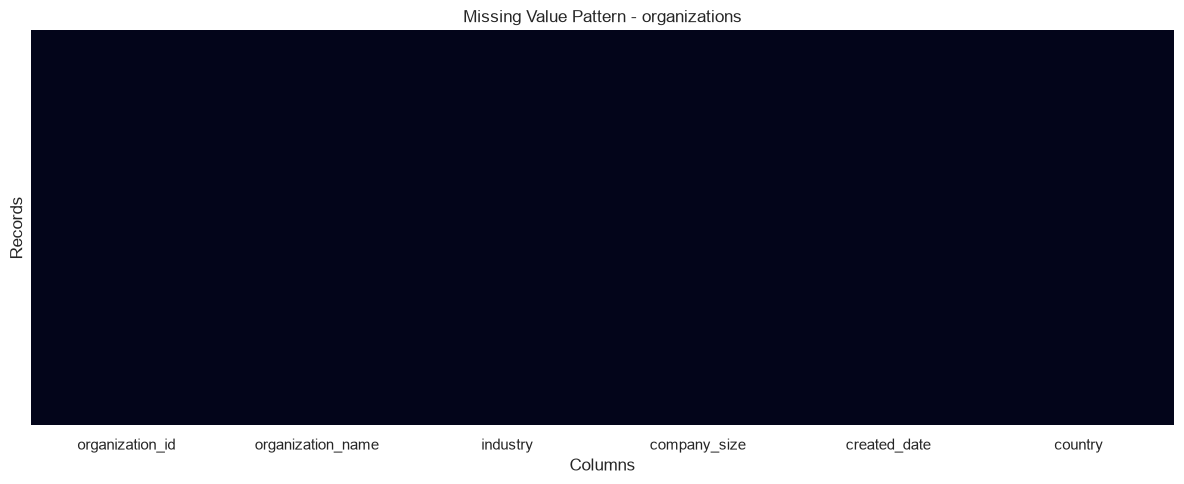

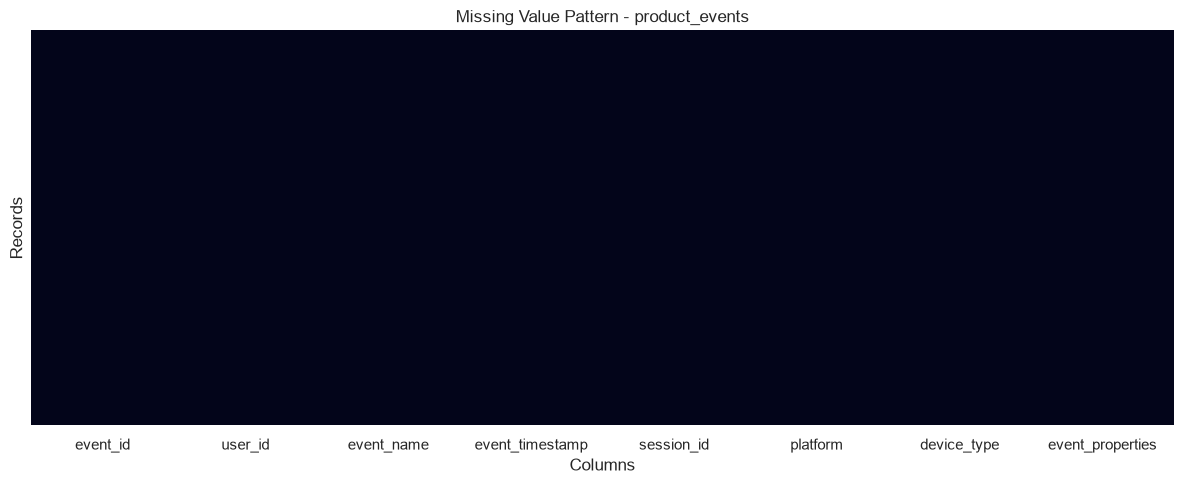

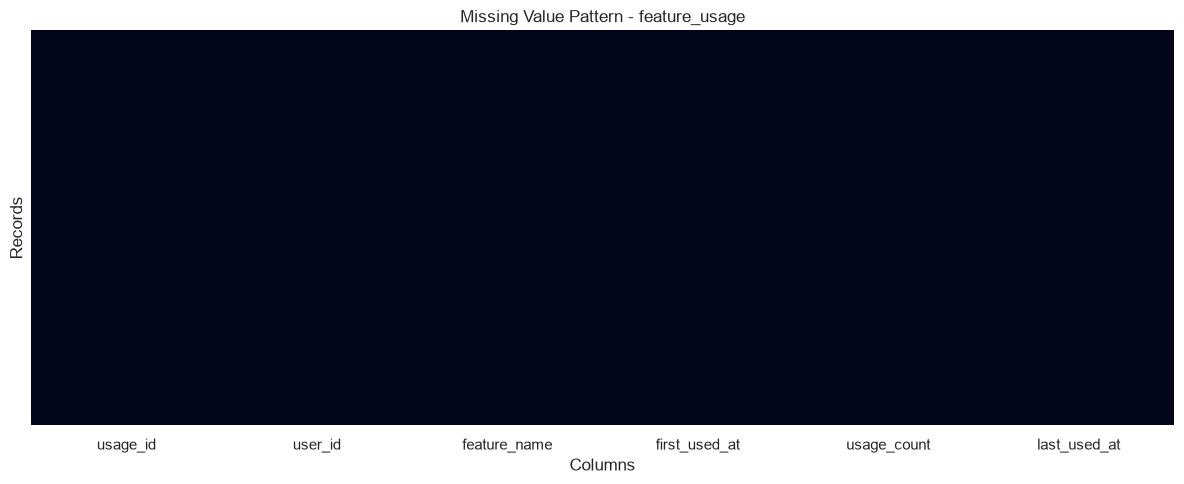

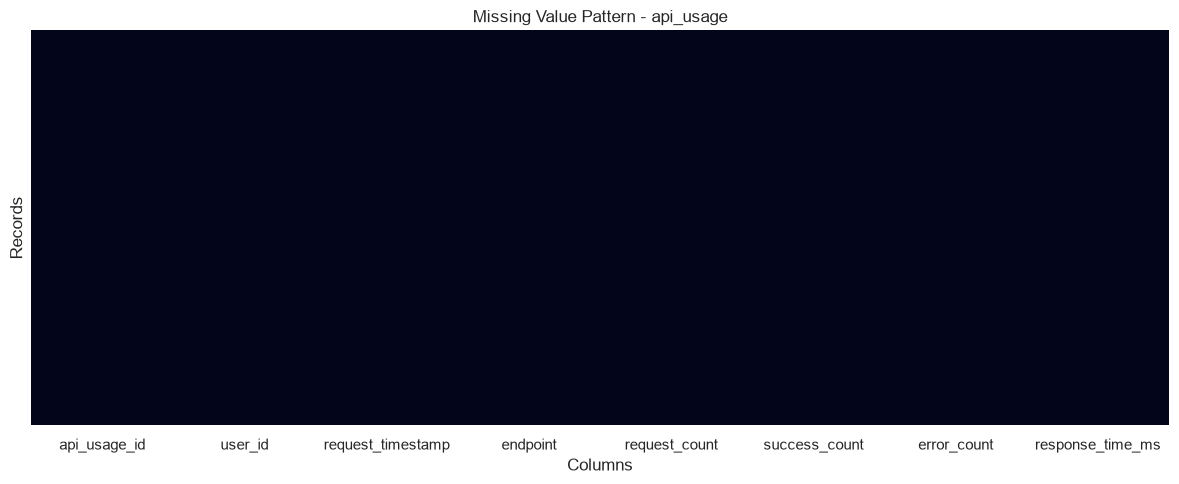

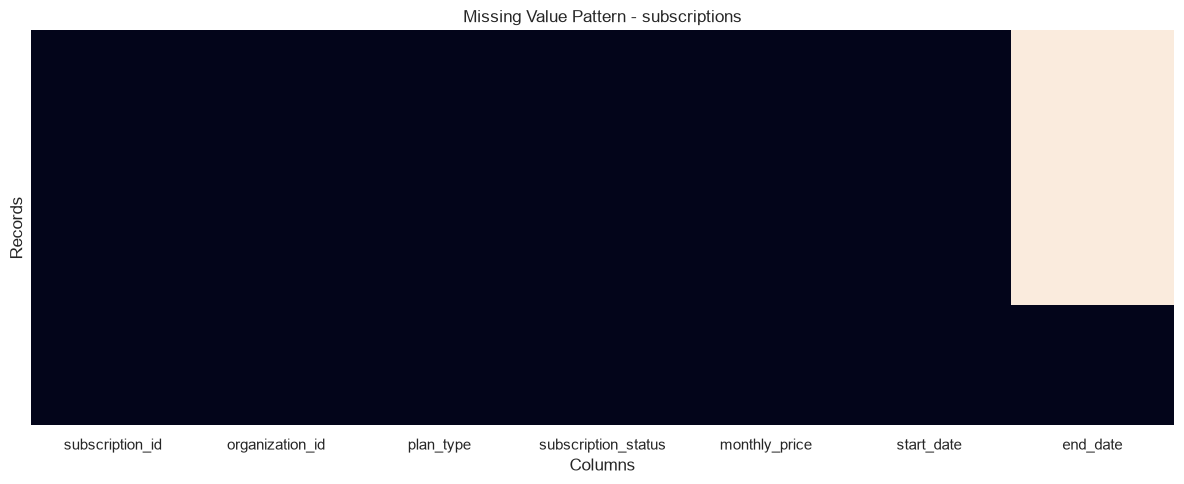

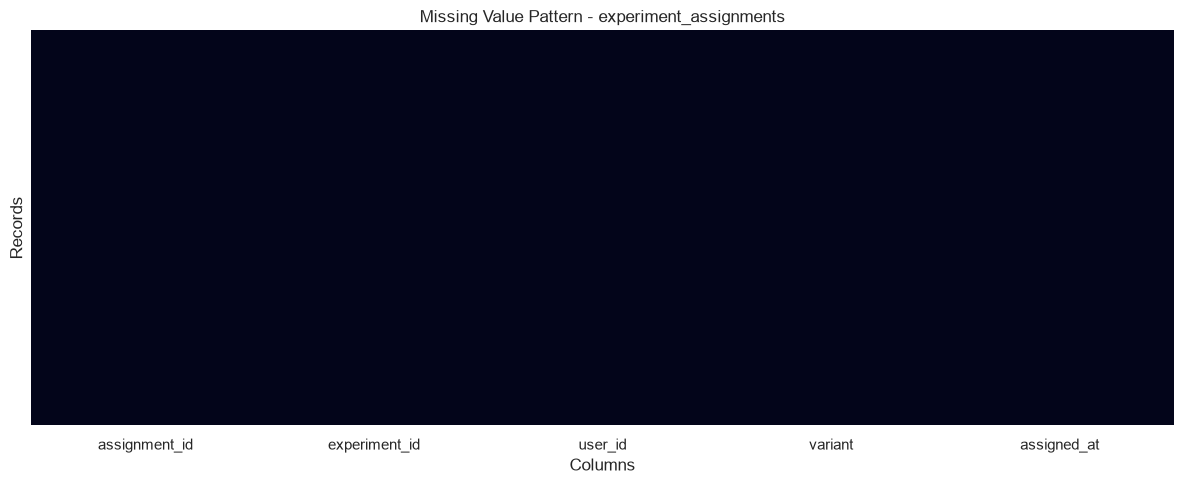

In [8]:
# Missing Values Heatmap

for table_name, df in dataframes.items():

    plt.figure(figsize=(12, 5))

    sns.heatmap(
        df.isnull(),
        cbar=False,
        yticklabels=False
    )

    plt.title(f"Missing Value Pattern - {table_name}")
    plt.xlabel("Columns")
    plt.ylabel("Records")

    plt.tight_layout()
    plt.show()

### Save the missing-value report :

In [9]:
import os

os.makedirs("../data/processed", exist_ok=True)

df_missing_values.to_csv(
    "../data/processed/missing_value_report.csv",
    index=False
)

df_missing_summary.to_csv(
    "../data/processed/missing_value_summary.csv",
    index=False
)

print("Missing value reports saved successfully.")

Missing value reports saved successfully.


### Duplicate Record Analysis:

In [10]:
# Duplicate Record Analysis

duplicate_results = []

for table_name, df in dataframes.items():

    total_rows = len(df)

    duplicate_rows = df.duplicated().sum()

    duplicate_percentage = (
        duplicate_rows / total_rows * 100
        if total_rows > 0 else 0
    )

    duplicate_results.append({
        "table_name": table_name,
        "total_rows": total_rows,
        "duplicate_rows": duplicate_rows,
        "duplicate_percentage": round(
            duplicate_percentage, 2
        )
    })

df_duplicate_summary = pd.DataFrame(duplicate_results)

display(df_duplicate_summary)

,table_name,total_rows,duplicate_rows,duplicate_percentage
0,users,10000,0,0.0
1,organizations,1500,0,0.0
2,product_events,80000,0,0.0
3,feature_usage,20041,0,0.0
4,api_usage,50000,0,0.0
5,subscriptions,1500,0,0.0
6,experiment_assignments,6000,0,0.0


### Check duplicate primary keys:

In [11]:
# Primary Key Duplicate Validation

primary_keys = {
    "users": "user_id",
    "organizations": "organization_id",
    "product_events": "event_id",
    "feature_usage": "usage_id",
    "api_usage": "api_usage_id",
    "subscriptions": "subscription_id",
    "experiment_assignments": "assignment_id"
}

primary_key_results = []

for table_name, primary_key in primary_keys.items():

    df = dataframes[table_name]

    duplicate_keys = df[primary_key].duplicated().sum()
    null_keys = df[primary_key].isnull().sum()

    primary_key_results.append({
        "table_name": table_name,
        "primary_key": primary_key,
        "duplicate_keys": duplicate_keys,
        "null_keys": null_keys
    })

df_primary_key_duplicates = pd.DataFrame(
    primary_key_results
)

display(df_primary_key_duplicates)

,table_name,primary_key,duplicate_keys,null_keys
0,users,user_id,0,0
1,organizations,organization_id,0,0
2,product_events,event_id,0,0
3,feature_usage,usage_id,0,0
4,api_usage,api_usage_id,0,0
5,subscriptions,subscription_id,0,0
6,experiment_assignments,assignment_id,0,0


### Save the duplicate reports :

In [12]:
df_duplicate_summary.to_csv(
    "../data/processed/duplicate_summary.csv",
    index=False
)

df_primary_key_duplicates.to_csv(
    "../data/processed/primary_key_duplicate_report.csv",
    index=False
)

print("Duplicate reports saved successfully.")

Duplicate reports saved successfully.


### Data Type Validation :

In [13]:
# Data Type Validation

dtype_results = []

for table_name, df in dataframes.items():

    for column in df.columns:

        dtype_results.append({
            "table_name": table_name,
            "column_name": column,
            "data_type": str(df[column].dtype),
            "missing_values": df[column].isnull().sum(),
            "unique_values": df[column].nunique()
        })

df_dtype_report = pd.DataFrame(dtype_results)

display(df_dtype_report)

,table_name,column_name,data_type,missing_values,unique_values
0,users,user_id,Int64,0,10000
1,users,organization_id,Int64,0,1499
2,users,signup_date,dbdate,0,884
3,users,country,str,0,8
4,users,user_role,str,0,5
5,users,acquisition_channel,str,0,5
6,users,is_verified,Int64,0,2
7,organizations,organization_id,Int64,0,1500
8,organizations,organization_name,str,0,1500
9,organizations,industry,str,0,6


### Inspect date columns separately :

In [14]:
# Date Column Validation

date_columns = {
    "users": ["signup_date"],
    "organizations": ["created_date"],
    "product_events": ["event_timestamp"],
    "feature_usage": ["first_used_at", "last_used_at"],
    "api_usage": ["request_timestamp"],
    "subscriptions": ["start_date", "end_date"],
    "experiment_assignments": ["assigned_at"]
}

date_type_results = []

for table_name, columns in date_columns.items():

    df = dataframes[table_name]

    for column in columns:

        date_type_results.append({
            "table_name": table_name,
            "column_name": column,
            "pandas_dtype": str(df[column].dtype),
            "sample_value": df[column].dropna().iloc[0]
        })

df_date_type_report = pd.DataFrame(date_type_results)

display(df_date_type_report)

,table_name,column_name,pandas_dtype,sample_value
0,users,signup_date,dbdate,2024-01-10
1,organizations,created_date,dbdate,2025-07-11
2,product_events,event_timestamp,dbdate,2024-01-31
3,feature_usage,first_used_at,dbdate,2026-06-14
4,feature_usage,last_used_at,dbdate,2026-07-07
5,api_usage,request_timestamp,dbdate,2025-06-06
6,subscriptions,start_date,dbdate,2024-09-13
7,subscriptions,end_date,dbdate,2026-03-14
8,experiment_assignments,assigned_at,dbdate,2024-03-31


### Save the reports :

In [15]:
df_dtype_report.to_csv(
    "../data/processed/data_type_report.csv",
    index=False
)

df_date_type_report.to_csv(
    "../data/processed/date_type_report.csv",
    index=False
)

print("Data type reports saved successfully.")

Data type reports saved successfully.


### Categorical Value Validation :

In [16]:
# Categorical Value Validation

categorical_columns = {
    "users": [
        "country",
        "user_role",
        "acquisition_channel"
    ],
    "organizations": [
        "industry",
        "company_size",
        "country"
    ],
    "product_events": [
        "event_name",
        "platform",
        "device_type",
        "event_properties"
    ],
    "feature_usage": [
        "feature_name"
    ],
    "api_usage": [
        "endpoint"
    ],
    "subscriptions": [
        "plan_type",
        "subscription_status"
    ],
    "experiment_assignments": [
        "experiment_id",
        "variant"
    ]
}

categorical_results = []

for table_name, columns in categorical_columns.items():

    df = dataframes[table_name]

    for column in columns:

        unique_values = df[column].dropna().unique()

        categorical_results.append({
            "table_name": table_name,
            "column_name": column,
            "unique_count": len(unique_values),
            "unique_values": sorted(
                [str(value) for value in unique_values]
            )
        })

df_categorical_report = pd.DataFrame(
    categorical_results
)

display(df_categorical_report)

,table_name,column_name,unique_count,unique_values
0,users,country,8,"[Bangladesh, Canada, Germany, India, Japan, Singapore, UK, USA]"
1,users,user_role,5,"[Admin, Data Analyst, Developer, Founder, Product Manager]"
2,users,acquisition_channel,5,"[Direct, Organic, Paid Ads, Referral, Social Media]"
3,organizations,industry,6,"[E-commerce, Education, Finance, Healthcare, Retail, Technology]"
4,organizations,company_size,5,"[Enterprise, Large, Medium, Small, Startup]"
5,organizations,country,8,"[Bangladesh, Canada, Germany, India, Japan, Singapore, UK, USA]"
6,product_events,event_name,10,"[analytics_dashboard_viewed, api_key_created, documentation_viewed, first_api_request, login, monitoring_enabled, sdk_integrated, signup, subscription_upgraded, webhook_created]"
7,product_events,platform,3,"[API, IDE, Web]"
8,product_events,device_type,2,"[Desktop, Mobile]"
9,product_events,event_properties,5,"[failure, feature_interaction, integration_action, page_view, success]"


### Check categorical value frequencies :

In [17]:
# Categorical Value Frequency

for table_name, columns in categorical_columns.items():

    df = dataframes[table_name]

    for column in columns:

        print("\n" + "=" * 60)
        print(f"TABLE: {table_name} | COLUMN: {column}")
        print("=" * 60)

        display(
            df[column]
            .value_counts(dropna=False)
            .reset_index(name="record_count")
            .rename(columns={"index": column})
        )


TABLE: users | COLUMN: country


,country,record_count
0,India,1370
1,Germany,1296
2,Singapore,1288
3,Japan,1241
4,Canada,1223
5,USA,1221
6,Bangladesh,1203
7,UK,1158



TABLE: users | COLUMN: user_role


,user_role,record_count
0,Founder,2041
1,Product Manager,2034
2,Admin,2000
3,Data Analyst,1979
4,Developer,1946



TABLE: users | COLUMN: acquisition_channel


,acquisition_channel,record_count
0,Social Media,2092
1,Paid Ads,2069
2,Organic,1959
3,Direct,1946
4,Referral,1934


... (22 outputs left out)


TABLE: experiment_assignments | COLUMN: experiment_id


,experiment_id,record_count
0,EXP_FEATURE_ONBOARDING_001,6000



TABLE: experiment_assignments | COLUMN: variant


,variant,record_count
0,Treatment,3003
1,Control,2997


### Save the categorical report :

In [18]:
df_categorical_report.to_csv(
    "../data/processed/categorical_value_report.csv",
    index=False
)

print("Categorical value report saved successfully.")

Categorical value report saved successfully.


### Numerical Outlier Analysis :

In [19]:
# Numerical Outlier Analysis

numerical_columns = {
    "users": ["is_verified"],
    "product_events": [],
    "feature_usage": ["usage_count"],
    "api_usage": [
        "request_count",
        "success_count",
        "error_count",
        "response_time_ms"
    ],
    "subscriptions": ["monthly_price"]
}

outlier_results = []

for table_name, columns in numerical_columns.items():

    df = dataframes[table_name]

    for column in columns:

        series = pd.to_numeric(df[column], errors="coerce").dropna()

        Q1 = series.quantile(0.25)
        Q3 = series.quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = series[
            (series < lower_bound) |
            (series > upper_bound)
        ]

        outlier_results.append({
            "table_name": table_name,
            "column_name": column,
            "minimum": series.min(),
            "maximum": series.max(),
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "outlier_count": len(outliers),
            "outlier_percentage": round(
                len(outliers) / len(series) * 100, 2
            )
        })

df_outlier_report = pd.DataFrame(outlier_results)

display(df_outlier_report)

,table_name,column_name,minimum,maximum,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
0,users,is_verified,0.00,1.00,1.0000,1.0000,0.000,1.00,1.00,2046,20.46
1,feature_usage,usage_count,1.00,500.00,121.0000,374.0000,253.000,-258.50,753.50,0,0.00
2,api_usage,request_count,10.00,1000.00,258.0000,750.0000,492.000,-480.00,1488.00,0,0.00
3,api_usage,success_count,8.00,965.00,245.0000,713.0000,468.000,-457.00,1415.00,0,0.00
4,api_usage,error_count,0.00,73.00,12.0000,37.0000,25.000,-25.50,74.50,0,0.00
5,api_usage,response_time_ms,20.02,999.97,263.8875,756.3125,492.425,-474.75,1494.95,0,0.00
6,subscriptions,monthly_price,0.00,199.00,0.0000,49.0000,49.000,-73.50,122.50,311,20.73


### Save the report :

In [20]:
df_outlier_report.to_csv(
    "../data/processed/numerical_outlier_report.csv",
    index=False
)

print("Numerical outlier report saved successfully.")

Numerical outlier report saved successfully.


### Correct the numerical outlier analysis :

In [21]:
# Numerical columns for outlier analysis

numerical_columns = {
    "feature_usage": ["usage_count"],
    "api_usage": [
        "request_count",
        "success_count",
        "error_count",
        "response_time_ms"
    ],
    "subscriptions": ["monthly_price"]
}

outlier_results = []

for table_name, columns in numerical_columns.items():

    df = dataframes[table_name]

    for column in columns:

        series = pd.to_numeric(
            df[column],
            errors="coerce"
        ).dropna()

        Q1 = series.quantile(0.25)
        Q3 = series.quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = series[
            (series < lower_bound) |
            (series > upper_bound)
        ]

        outlier_results.append({
            "table_name": table_name,
            "column_name": column,
            "minimum": series.min(),
            "maximum": series.max(),
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "outlier_count": len(outliers),
            "outlier_percentage": round(
                len(outliers) / len(series) * 100, 2
            )
        })

df_outlier_report = pd.DataFrame(outlier_results)

display(df_outlier_report)

,table_name,column_name,minimum,maximum,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
0,feature_usage,usage_count,1.00,500.00,121.0000,374.0000,253.000,-258.50,753.50,0,0.00
1,api_usage,request_count,10.00,1000.00,258.0000,750.0000,492.000,-480.00,1488.00,0,0.00
2,api_usage,success_count,8.00,965.00,245.0000,713.0000,468.000,-457.00,1415.00,0,0.00
3,api_usage,error_count,0.00,73.00,12.0000,37.0000,25.000,-25.50,74.50,0,0.00
4,api_usage,response_time_ms,20.02,999.97,263.8875,756.3125,492.425,-474.75,1494.95,0,0.00
5,subscriptions,monthly_price,0.00,199.00,0.0000,49.0000,49.000,-73.50,122.50,311,20.73


### Validate API usage consistency :

In [22]:
# API Usage Consistency Validation

api_df = dataframes["api_usage"].copy()

api_df["calculated_total"] = (
    api_df["success_count"] +
    api_df["error_count"]
)

api_df["count_difference"] = (
    api_df["request_count"] -
    api_df["calculated_total"]
)

display(
    api_df[
        api_df["count_difference"] != 0
    ].head(20)
)

print(
    "Inconsistent API records:",
    (api_df["count_difference"] != 0).sum()
)

,api_usage_id,user_id,request_timestamp,endpoint,request_count,success_count,error_count,response_time_ms,calculated_total,count_difference


Inconsistent API records: 0


### Inspect subscription prices :

In [23]:
# Subscription Price Distribution

subscription_df = dataframes["subscriptions"]

display(
    subscription_df.groupby("plan_type")["monthly_price"]
    .agg(["count", "min", "max", "mean", "median"])
    .round(2)
)

,count,min,max,mean,median
plan_type,,,,,
Enterprise,311,199.0,199.0,199.0,199.0
Free,609,0.0,0.0,0.0,0.0
Pro,580,49.0,49.0,49.0,49.0


### Date Consistency Validation :

#### Check 1: Feature usage dates :

In [24]:
# Feature Usage Date Validation

feature_df = dataframes["feature_usage"]

invalid_feature_dates = feature_df[
    feature_df["last_used_at"] < feature_df["first_used_at"]
]

print("Invalid feature date records:", len(invalid_feature_dates))

display(invalid_feature_dates.head(10))

Invalid feature date records: 0


,usage_id,user_id,feature_name,first_used_at,usage_count,last_used_at


#### Check 2: Subscription dates :

In [25]:
# Subscription Date Validation

subscription_df = dataframes["subscriptions"]

invalid_subscription_dates = subscription_df[
    subscription_df["end_date"].notna() &
    (subscription_df["end_date"] < subscription_df["start_date"])
]

print(
    "Invalid subscription date records:",
    len(invalid_subscription_dates)
)

display(invalid_subscription_dates.head(10))

Invalid subscription date records: 0


,subscription_id,organization_id,plan_type,subscription_status,monthly_price,start_date,end_date


### Check 3: User and organization dates:

In [26]:
# User and Organization Date Validation

users_df = dataframes["users"]
organizations_df = dataframes["organizations"]

user_org_df = users_df.merge(
    organizations_df[
        ["organization_id", "created_date"]
    ],
    on="organization_id",
    how="left"
)

invalid_user_dates = user_org_df[
    user_org_df["signup_date"] < user_org_df["created_date"]
]

print("Users signed up before organization creation:",
      len(invalid_user_dates))

display(invalid_user_dates.head(10))

Users signed up before organization creation: 0


,user_id,organization_id,signup_date,country,user_role,acquisition_channel,is_verified,created_date


#### Check 4: API request dates :

In [27]:
# API Request Date Validation

api_df = dataframes["api_usage"]

user_signup_df = users_df[
    ["user_id", "signup_date"]
]

api_user_df = api_df.merge(
    user_signup_df,
    on="user_id",
    how="left"
)

invalid_api_dates = api_user_df[
    api_user_df["request_timestamp"] < api_user_df["signup_date"]
]

print("API requests before user signup:", len(invalid_api_dates))

display(invalid_api_dates.head(10))

API requests before user signup: 0


,api_usage_id,user_id,request_timestamp,endpoint,request_count,success_count,error_count,response_time_ms,signup_date


### Create the final preprocessing summary :

In [28]:
# Final Data Preprocessing Summary

preprocessing_summary = pd.DataFrame([
    {
        "validation": "Missing Value Analysis",
        "result": "Only subscriptions.end_date contains missing values",
        "status": "Reviewed"
    },
    {
        "validation": "Full Row Duplicate Analysis",
        "result": "Zero duplicate records across 7 tables",
        "status": "Passed"
    },
    {
        "validation": "Primary Key Validation",
        "result": "Zero duplicate or NULL primary keys",
        "status": "Passed"
    },
    {
        "validation": "Data Type Validation",
        "result": "Data types inspected across all columns",
        "status": "Reviewed"
    },
    {
        "validation": "Categorical Value Validation",
        "result": "16 categorical columns inspected",
        "status": "Reviewed"
    },
    {
        "validation": "Numerical Outlier Analysis",
        "result": "No IQR outliers except expected subscription price differences",
        "status": "Reviewed"
    },
    {
        "validation": "API Usage Consistency",
        "result": "Zero inconsistent API records",
        "status": "Passed"
    },
    {
        "validation": "Feature Usage Date Validation",
        "result": "Zero invalid records",
        "status": "Passed"
    },
    {
        "validation": "Subscription Date Validation",
        "result": "Zero invalid records",
        "status": "Passed"
    },
    {
        "validation": "User Organization Date Validation",
        "result": "Zero invalid records",
        "status": "Passed"
    },
    {
        "validation": "API Request Date Validation",
        "result": "Zero invalid records",
        "status": "Passed"
    }
])

display(preprocessing_summary)

,validation,result,status
0,Missing Value Analysis,Only subscriptions.end_date contains missing values,Reviewed
1,Full Row Duplicate Analysis,Zero duplicate records across 7 tables,Passed
2,Primary Key Validation,Zero duplicate or NULL primary keys,Passed
3,Data Type Validation,Data types inspected across all columns,Reviewed
4,Categorical Value Validation,16 categorical columns inspected,Reviewed
5,Numerical Outlier Analysis,No IQR outliers except expected subscription price differences,Reviewed
6,API Usage Consistency,Zero inconsistent API records,Passed
7,Feature Usage Date Validation,Zero invalid records,Passed
8,Subscription Date Validation,Zero invalid records,Passed
9,User Organization Date Validation,Zero invalid records,Passed


#### Save the summary:

In [29]:
preprocessing_summary.to_csv(
    "../data/processed/preprocessing_summary.csv",
    index=False
)

print("Preprocessing summary saved successfully.")

Preprocessing summary saved successfully.
